---
title: "Chapter 3: Functions"
subtitle: Notes drawn from OpenStax *Algebra and Trigonometry 2e* (§3.1–3.7) and *Precalculus 2e*
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "lines.linewidth": 2,
    "legend.frameon": True, "legend.facecolor": "#fcfcfb", "legend.edgecolor": "none", "legend.framealpha": 0.92, "figure.dpi": 110,
})

def setup(ax, xlim, ylim, title=None, ticks=1):
    """Axes through the origin, light grid, square units."""
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    for s in ("left", "bottom"):
        ax.spines[s].set_position("zero"); ax.spines[s].set_color(INK2)
    for s in ("right", "top"):
        ax.spines[s].set_visible(False)
    ax.set_xticks(np.arange(np.ceil(xlim[0]), xlim[1] + 0.01, ticks))
    ax.set_yticks(np.arange(np.ceil(ylim[0]), ylim[1] + 0.01, ticks))
    ax.tick_params(labelsize=8)
    ax.grid(color="#e6e5e0", linewidth=0.6); ax.set_axisbelow(True)
    ax.set_aspect("equal")
    if title: ax.set_title(title)

def dot(ax, x, y, filled=True, color=BLUE):
    ax.plot(x, y, "o", ms=7, color=color,
            mfc=color if filled else "#fcfcfb", mew=2, zorder=5)

Matplotlib is building the font cache; this may take a moment.


(sec-3-1)=
## 3.1 Functions and Function Notation

### Relations and functions

- A **relation** is any set of ordered pairs $(x, y)$. The set of inputs is the **domain**; the set of outputs is the **range**.
- A **function** is a relation in which **each input has exactly one output**. Outputs may repeat; inputs may not lead to two different outputs.
- $f(x)$ is read "$f$ of $x$" and means *the output of $f$ at input $x$*. It is **not** $f$ times $x$.

| Task | Question it answers | How |
|---|---|---|
| **Evaluate** $f(a)$ | Input known; what is the output? | Substitute $a$ for every $x$ |
| **Solve** $f(x) = c$ | Output known; which input(s) give it? | Set the formula equal to $c$ and solve for $x$ |

A function can be given as a formula, a table, a graph, or words. To get a formula from an equation such as $2x + 3y = 6$, solve for the output: $y = f(x) = 2 - \tfrac{2}{3}x$. If solving gives a $\pm$ (as with $x^2 + y^2 = 1$, where $y = \pm\sqrt{1 - x^2}$), $y$ is **not** a function of $x$.

**Worked example.** Let $f(x) = x^2 - 3x$.

$$
\begin{aligned}
f(-2) &= (-2)^2 - 3(-2) = 4 + 6 = 10 \\[4pt]
f(a + h) &= (a + h)^2 - 3(a + h) = a^2 + 2ah + h^2 - 3a - 3h \\[4pt]
f(x) = 4 &\implies x^2 - 3x - 4 = 0 \implies (x - 4)(x + 1) = 0 \implies x = 4 \text{ or } x = -1
\end{aligned}
$$

Two inputs give the output $4$, which is allowed for a function, but it means $f$ is not one-to-one.

### One-to-one functions and the line tests

A function is **one-to-one** if each output comes from only one input. Algebraically: $f(a) = f(b)$ forces $a = b$.

| Test | Draw | Passes if every line hits the graph | Tells you |
|---|---|---|---|
| Vertical line test | vertical lines $x = c$ | at most once | the graph is a function of $x$ |
| Horizontal line test | horizontal lines $y = c$ | at most once | the function is one-to-one |

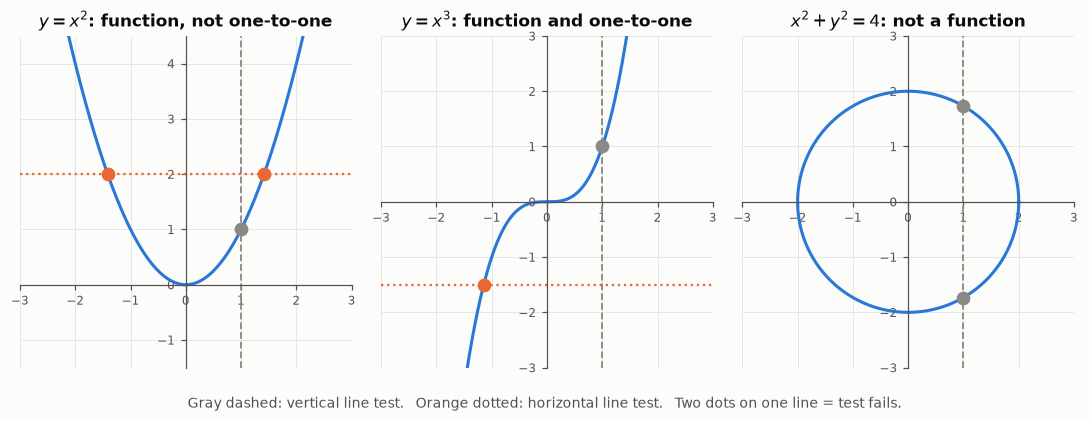

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
x = np.linspace(-3, 3, 400)

ax = axes[0]; setup(ax, (-3, 3), (-1.5, 4.5), "$y = x^2$: function, not one-to-one")
ax.plot(x, x**2, color=BLUE)
ax.axvline(1, color=GRAY, ls="--", lw=1.2); dot(ax, 1, 1, color=GRAY)
ax.axhline(2, color=ORANGE, ls=":", lw=1.5)
for xi in (-np.sqrt(2), np.sqrt(2)): dot(ax, xi, 2, color=ORANGE)

ax = axes[1]; setup(ax, (-3, 3), (-3, 3), "$y = x^3$: function and one-to-one")
ax.plot(x, x**3, color=BLUE)
ax.axvline(1, color=GRAY, ls="--", lw=1.2); dot(ax, 1, 1, color=GRAY)
ax.axhline(-1.5, color=ORANGE, ls=":", lw=1.5); dot(ax, -np.cbrt(1.5), -1.5, color=ORANGE)

ax = axes[2]; setup(ax, (-3, 3), (-3, 3), "$x^2 + y^2 = 4$: not a function")
t = np.linspace(0, 2*np.pi, 400); ax.plot(2*np.cos(t), 2*np.sin(t), color=BLUE)
ax.axvline(1, color=GRAY, ls="--", lw=1.2)
for yi in (np.sqrt(3), -np.sqrt(3)): dot(ax, 1, yi, color=GRAY)

fig.text(0.5, -0.02, "Gray dashed: vertical line test.   Orange dotted: horizontal line test.   "
         "Two dots on one line = test fails.", ha="center", color=INK2, fontsize=9)
plt.tight_layout(); plt.show()

### Toolkit functions

You should be able to sketch each of these from memory. Every transformation in §3.5 starts from one of them.

| Name | Formula | Domain | Range |
|---|---|---|---|
| Constant | $f(x) = c$ | $(-\infty, \infty)$ | $\{c\}$ |
| Identity | $f(x) = x$ | $(-\infty, \infty)$ | $(-\infty, \infty)$ |
| Absolute value | $f(x) = \lvert x \rvert$ | $(-\infty, \infty)$ | $[0, \infty)$ |
| Quadratic | $f(x) = x^2$ | $(-\infty, \infty)$ | $[0, \infty)$ |
| Cubic | $f(x) = x^3$ | $(-\infty, \infty)$ | $(-\infty, \infty)$ |
| Reciprocal | $f(x) = \dfrac{1}{x}$ | $(-\infty, 0) \cup (0, \infty)$ | $(-\infty, 0) \cup (0, \infty)$ |
| Reciprocal squared | $f(x) = \dfrac{1}{x^2}$ | $(-\infty, 0) \cup (0, \infty)$ | $(0, \infty)$ |
| Square root | $f(x) = \sqrt{x}$ | $[0, \infty)$ | $[0, \infty)$ |
| Cube root | $f(x) = \sqrt[3]{x}$ | $(-\infty, \infty)$ | $(-\infty, \infty)$ |

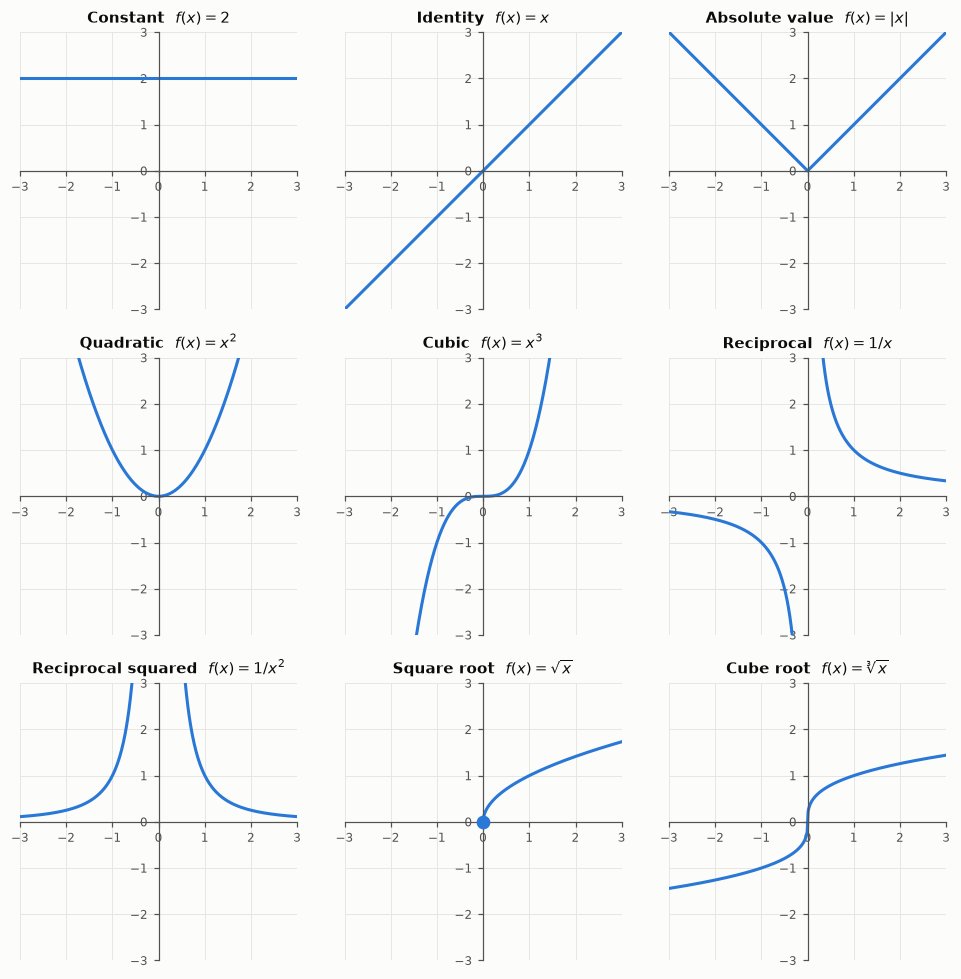

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
x = np.linspace(-3, 3, 601)
xn, xp = np.linspace(-3, -0.05, 300), np.linspace(0.05, 3, 300)
specs = [
    ("Constant  $f(x)=2$", lambda a: [(x, np.full_like(x, 2))]),
    ("Identity  $f(x)=x$", lambda a: [(x, x)]),
    (r"Absolute value  $f(x)=|x|$", lambda a: [(x, np.abs(x))]),
    ("Quadratic  $f(x)=x^2$", lambda a: [(x, x**2)]),
    ("Cubic  $f(x)=x^3$", lambda a: [(x, x**3)]),
    ("Reciprocal  $f(x)=1/x$", lambda a: [(xn, 1/xn), (xp, 1/xp)]),
    ("Reciprocal squared  $f(x)=1/x^2$", lambda a: [(xn, 1/xn**2), (xp, 1/xp**2)]),
    (r"Square root  $f(x)=\sqrt{x}$", lambda a: [(x[x >= 0], np.sqrt(x[x >= 0]))]),
    (r"Cube root  $f(x)=\sqrt[3]{x}$", lambda a: [(x, np.cbrt(x))]),
]
for ax, (title, pieces) in zip(axes.flat, specs):
    setup(ax, (-3, 3), (-3, 3)); ax.set_title(title, fontsize=10)
    for xs, ys in pieces(ax):
        ys = np.where(np.abs(ys) > 3.5, np.nan, ys)
        ax.plot(xs, ys, color=BLUE)
dot(axes[2, 1], 0, 0)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- $f(x + 2) \neq f(x) + 2$ and $f(2x) \neq 2f(x)$. Substitute the whole input for **every** $x$: if $f(x) = x^2$, then $f(x + 2) = (x + 2)^2$.
- Mixing up the direction of "is a function of." Price is a function of the menu item (each item has one price). Item is not a function of price if two items cost the same.
- Repeated **outputs** do not break the function rule. Repeated outputs break *one-to-one*.
- When solving $f(x) = c$, report every input that works, not just the first one you find.
:::

:::{important} The book underplays this
The algebraic test for one-to-one is worth knowing now: assume $f(a) = f(b)$ and see if you are forced to $a = b$. For $f(x) = 3x - 7$: $3a - 7 = 3b - 7 \implies a = b$, so it is one-to-one. For $f(x) = x^2$: $a^2 = b^2$ only gives $a = \pm b$, so it is not. The graph test fails you as soon as you can't draw the graph exactly; this test doesn't.
:::

:::{tip} Where this shows up
A regression model is a function: the mean response $E[Y \mid x] = \beta_0 + \beta_1 x$ assigns one value to each $x$. Raw data generally are *not* a function (one elevation, many counts), which is exactly why we model the mean. Probability density functions and CDFs are functions, and a strictly increasing CDF is one-to-one, which is what lets you invert it in §3.7.
:::

(sec-3-2)=
## 3.2 Domain and Range

### Finding the domain from a formula

Start with all real numbers, then remove inputs that force an undefined operation.

| Feature in the formula | Restriction |
|---|---|
| Denominator $Q(x)$ | exclude every $x$ with $Q(x) = 0$ |
| Even root $\sqrt{R(x)}$, $\sqrt[4]{R(x)}$, … | require $R(x) \ge 0$ |
| Even root **in a denominator** | require $R(x) > 0$ |
| Polynomials, odd roots | no restriction |

**Worked example.** Domain of $f(x) = \dfrac{\sqrt{7 - x}}{x - 2}$:

$$
7 - x \ge 0 \implies x \le 7, \qquad x - 2 \ne 0 \implies x \ne 2
\qquad\Longrightarrow\qquad (-\infty, 2) \cup (2, 7]
$$

### Three notations

| Inequality | Set-builder | Interval |
|---|---|---|
| $-1 < x \le 4$ | $\{x \mid -1 < x \le 4\}$ | $(-1, 4]$ |
| $x \ge 3$ | $\{x \mid x \ge 3\}$ | $[3, \infty)$ |
| $x \ne 2$ | $\{x \mid x \ne 2\}$ | $(-\infty, 2) \cup (2, \infty)$ |

- Parenthesis = endpoint excluded; bracket = included. $\infty$ and $-\infty$ always get parentheses.
- $\cup$ (union) joins pieces that are not connected.

### Domain and range from a graph

Project the graph onto each axis: the shadow on the $x$-axis is the domain, the shadow on the $y$-axis is the range. Watch for arrows (the graph continues), open circles (excluded), and closed circles (included).

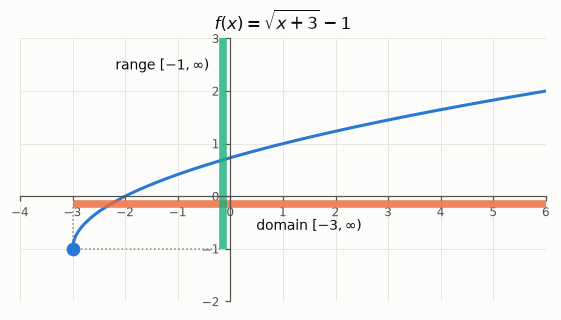

In [4]:
fig, ax = plt.subplots(figsize=(5.2, 4))
setup(ax, (-4, 6), (-2, 3), r"$f(x) = \sqrt{x + 3} - 1$")
x = np.linspace(-3, 6, 400); ax.plot(x, np.sqrt(x + 3) - 1, color=BLUE)
dot(ax, -3, -1)
ax.annotate("", xy=(6.1, np.sqrt(9.1) - 1), xytext=(5.6, np.sqrt(8.6) - 1),
            arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=2))
ax.plot([-3, 6], [-0.15, -0.15], color=ORANGE, lw=5, alpha=0.8, solid_capstyle="butt")
ax.plot([-0.15, -0.15], [-1, 3], color=AQUA, lw=5, alpha=0.8, solid_capstyle="butt")
ax.text(1.5, -0.65, r"domain $[-3, \infty)$", color=INK, ha="center", fontsize=9)
ax.text(-0.4, 2.4, r"range $[-1, \infty)$", color=INK, ha="right", fontsize=9)
ax.plot([-3, -3], [-1, -0.15], color=GRAY, ls=":", lw=1)
ax.plot([-3, -0.15], [-1, -1], color=GRAY, ls=":", lw=1)
plt.tight_layout(); plt.show()

### Piecewise functions

A **piecewise function** uses different formulas on different parts of the domain. To evaluate, check which **condition on $x$** the input satisfies, then use only that formula.

**Worked example.**

$$
f(x) =
\begin{cases}
x + 1, & x < 0 \\
x^2, & 0 \le x \le 2 \\
1, & x > 2
\end{cases}
\qquad
f(-3) = -2, \quad f(0) = 0, \quad f(2) = 4, \quad f(5) = 1
$$

To graph, draw each formula only on its own interval, with open circles at excluded endpoints and closed circles at included ones. Domain: $(-\infty, \infty)$. Range: the union of each piece's outputs, $(-\infty, 1) \cup [0, 4] \cup \{1\} = (-\infty, 4]$.

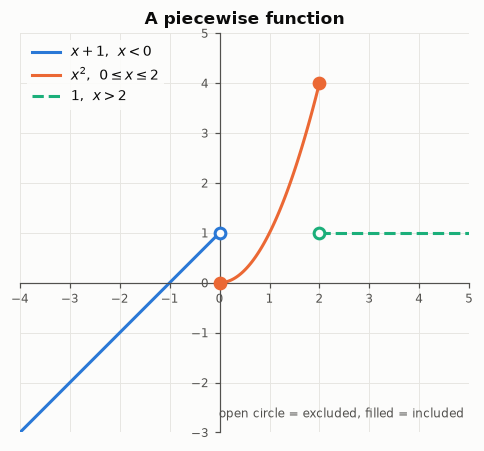

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
setup(ax, (-4, 5), (-3, 5), "A piecewise function")
x1 = np.linspace(-4, 0, 100); ax.plot(x1, x1 + 1, color=BLUE, label="$x + 1$,  $x < 0$")
x2 = np.linspace(0, 2, 100); ax.plot(x2, x2**2, color=ORANGE, label="$x^2$,  $0 \\leq x \\leq 2$")
x3 = np.linspace(2, 5, 100); ax.plot(x3, np.ones_like(x3), color=AQUA, ls="--", label="$1$,  $x > 2$")
dot(ax, 0, 1, filled=False, color=BLUE); dot(ax, 0, 0, color=ORANGE)
dot(ax, 2, 4, color=ORANGE); dot(ax, 2, 1, filled=False, color=AQUA)
ax.legend(loc="upper left", fontsize=9)
ax.text(4.9, -2.7, "open circle = excluded, filled = included", ha="right", color=INK2, fontsize=8)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Writing $[3, \infty]$. Infinity is never included.
- Reading the domain off a *simplified* formula. $\dfrac{x^2 - 4}{x - 2}$ simplifies to $x + 2$, but the domain still excludes $x = 2$.
- Handling only one restriction when there are two (a root *and* a denominator).
- In a piecewise function, choosing the formula by the output instead of by the condition on the input.
- Getting the range of a piecewise function from the endpoints only. Find each piece's outputs, then take the union.
:::

:::{tip} Where this shows up
Every parameter has a domain: a probability $p \in [0, 1]$, a standard deviation $\sigma \in (0, \infty)$, a count $\lambda > 0$. In Bayesian work (Hoff), a prior must live on the parameter's domain, which is why you see half-normal or gamma priors on $\sigma$ rather than a plain normal. Piecewise functions are segmented (hinge) regression and threshold models, e.g., a species response that is flat below a temperature and declines above it.
:::

(sec-3-3)=
## 3.3 Rates of Change and Behavior of Graphs

### Average rate of change

$$
\text{average rate of change on } [a, b] = \frac{\Delta y}{\Delta x} = \frac{f(b) - f(a)}{b - a}
$$

- Geometrically, it is the **slope of the secant line** through $(a, f(a))$ and $(b, f(b))$.
- Units are output units per input unit (e.g., animals per year).
- It uses only the two endpoints, so it says nothing about what happens in between.

**Worked example.** $f(x) = x^2 - 3x$ on $[1, 4]$: $f(4) = 4$, $f(1) = -2$, so

$$
\frac{f(4) - f(1)}{4 - 1} = \frac{4 - (-2)}{3} = 2.
$$

**As an expression.** Replacing the interval $[a, b]$ with $[a, a + h]$:

$$
\begin{aligned}
\frac{f(a + h) - f(a)}{h}
&= \frac{\big[(a + h)^2 - 3(a + h)\big] - \big[a^2 - 3a\big]}{h} \\
&= \frac{2ah + h^2 - 3h}{h} = 2a + h - 3, \quad h \ne 0
\end{aligned}
$$

Check: $a = 1$, $h = 3$ gives $2 + 3 - 3 = 2$, matching the result above.

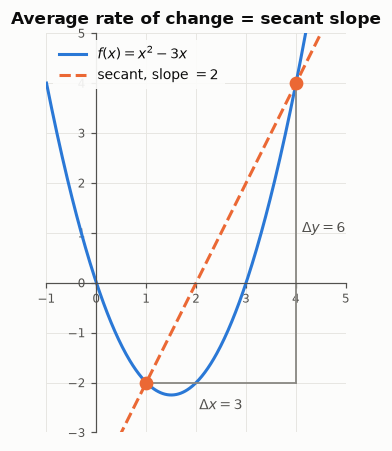

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
setup(ax, (-1, 5), (-3, 5), "Average rate of change = secant slope")
x = np.linspace(-1, 5, 400); f = lambda t: t**2 - 3*t
ax.plot(x, f(x), color=BLUE, label="$f(x) = x^2 - 3x$")
ax.plot(x, f(1) + 2*(x - 1), color=ORANGE, ls="--", label="secant, slope $= 2$")
dot(ax, 1, f(1), color=ORANGE); dot(ax, 4, f(4), color=ORANGE)
ax.plot([1, 4], [-2, -2], color=GRAY, lw=1.2); ax.plot([4, 4], [-2, 4], color=GRAY, lw=1.2)
ax.text(2.5, -2.55, r"$\Delta x = 3$", ha="center", color=INK2, fontsize=9)
ax.text(4.12, 1, r"$\Delta y = 6$", color=INK2, fontsize=9)
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()

### Increasing, decreasing, and extrema

| Term | Definition |
|---|---|
| Increasing on an interval | $x_1 < x_2 \implies f(x_1) < f(x_2)$ (positive rate of change) |
| Decreasing on an interval | $x_1 < x_2 \implies f(x_1) > f(x_2)$ (negative rate of change) |
| Local maximum at $x = b$ | $f(b) \ge f(x)$ for all $x$ in some open interval around $b$ |
| Local minimum at $x = b$ | $f(b) \le f(x)$ for all $x$ in some open interval around $b$ |
| Absolute maximum / minimum | the largest / smallest output over the **entire** domain (may not exist) |

- State increasing/decreasing intervals using **$x$-values**, with open intervals.
- A local max is where the graph switches from increasing to decreasing; a local min is the reverse. "The local maximum is $2$, at $x = -1$": the max is the $y$-value; the location is the $x$-value.

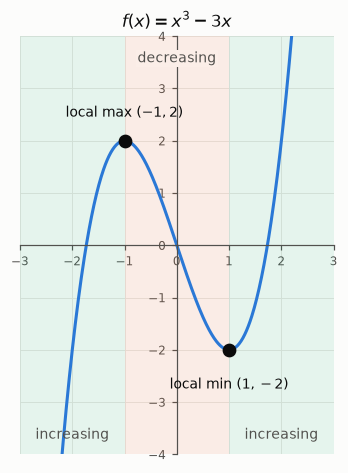

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4.4))
setup(ax, (-3, 3), (-4, 4), "$f(x) = x^3 - 3x$")
x = np.linspace(-2.3, 2.3, 400); f = lambda t: t**3 - 3*t
ax.axvspan(-3, -1, color=AQUA, alpha=0.10, lw=0); ax.axvspan(1, 3, color=AQUA, alpha=0.10, lw=0)
ax.axvspan(-1, 1, color=ORANGE, alpha=0.10, lw=0)
ax.plot(x, f(x), color=BLUE)
dot(ax, -1, 2, color=INK); dot(ax, 1, -2, color=INK)
ax.text(-1, 2.45, "local max $(-1, 2)$", ha="center", fontsize=9)
ax.text(1, -2.75, "local min $(1, -2)$", ha="center", fontsize=9)
ax.text(-2, -3.7, "increasing", ha="center", color=INK2, fontsize=9)
ax.text(0, 3.5, "decreasing", ha="center", color=INK2, fontsize=9, bbox=dict(fc="#fbeee8", ec="none", pad=1))
ax.text(2, -3.7, "increasing", ha="center", color=INK2, fontsize=9)
plt.tight_layout(); plt.show()

Reading the graph: increasing on $(-\infty, -1) \cup (1, \infty)$, decreasing on $(-1, 1)$. There is no absolute max or min, because the graph goes to $\pm\infty$.

:::{admonition} Common mistakes
:class: warning
- Mismatched order: $\dfrac{f(b) - f(a)}{a - b}$ flips the sign. Whatever goes first on top goes first on the bottom.
- Dropping the brackets around $f(a)$ in the difference quotient. The minus applies to **every** term of $f(a)$.
- Reporting increasing/decreasing intervals in $y$-values.
- Calling a local max the largest value on the whole graph. "Local" only means larger than its neighbors.
:::

:::{important} The book underplays this
The difference quotient $\dfrac{f(a + h) - f(a)}{h}$ gets a single example in the book, but it is the definition of the derivative once you let $h \to 0$. Stewart opens with it. Do every "find the average rate of change as an expression" exercise.
:::

:::{tip} Where this shows up
Population growth over a survey interval, $\dfrac{N(t_2) - N(t_1)}{t_2 - t_1}$, is an average rate of change. Maximum likelihood estimation finds where a likelihood switches from increasing to decreasing: the MLE is an absolute maximum, and the posterior mode in Bayesian analysis is the same idea.
:::

(sec-3-4)=
## 3.4 Composition of Functions

### Combining functions

| Operation | Definition | Domain |
|---|---|---|
| Sum / difference | $(f \pm g)(x) = f(x) \pm g(x)$ | $\operatorname{dom} f \cap \operatorname{dom} g$ |
| Product | $(fg)(x) = f(x)\,g(x)$ | $\operatorname{dom} f \cap \operatorname{dom} g$ |
| Quotient | $\left(\dfrac{f}{g}\right)(x) = \dfrac{f(x)}{g(x)}$ | $\operatorname{dom} f \cap \operatorname{dom} g$, and $g(x) \ne 0$ |
| Composition | $(f \circ g)(x) = f\big(g(x)\big)$ | $x \in \operatorname{dom} g$ **and** $g(x) \in \operatorname{dom} f$ |

### Composition

- In $f(g(x))$, $g$ is the **inner** function and acts first; its output becomes the input to $f$.
- From a table or graph: find $g(a)$ first, then look up $f$ at that value.
- Order matters. In general $f \circ g \ne g \circ f$.
- $f \circ g$ is not multiplication: $(f \circ g)(x) \ne f(x)\,g(x)$.

**Worked example (order).** $f(x) = x^2$, $g(x) = x + 3$:

$$
f\big(g(x)\big) = (x + 3)^2, \qquad g\big(f(x)\big) = x^2 + 3
$$

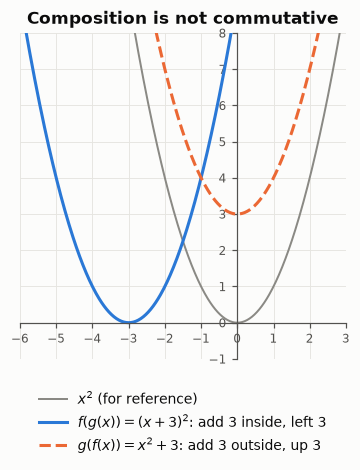

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 4.4))
setup(ax, (-6, 3), (-1, 8), r"Composition is not commutative")
x = np.linspace(-6, 3, 400)
ax.plot(x, x**2, color=GRAY, lw=1.3, label="$x^2$ (for reference)")
ax.plot(x, (x + 3)**2, color=BLUE, label=r"$f(g(x)) = (x + 3)^2$: add 3 inside, left 3")
ax.plot(x, x**2 + 3, color=ORANGE, ls="--", label=r"$g(f(x)) = x^2 + 3$: add 3 outside, up 3")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.06), fontsize=9)
plt.tight_layout(); plt.show()

### Domain of a composition

Two checks: the input must be allowed in $g$, and $g$'s output must be allowed in $f$.

**Worked example.** $f(x) = \dfrac{1}{x - 2}$, $g(x) = \sqrt{x + 1}$, so $f\big(g(x)\big) = \dfrac{1}{\sqrt{x + 1} - 2}$.

$$
\begin{aligned}
x \in \operatorname{dom} g: &\quad x + 1 \ge 0 \implies x \ge -1 \\
g(x) \in \operatorname{dom} f: &\quad \sqrt{x + 1} \ne 2 \implies x \ne 3 \\
\text{Domain:} &\quad [-1, 3) \cup (3, \infty)
\end{aligned}
$$

### Decomposition

Reverse the process: find an inner $g$ and outer $f$ with $h = f \circ g$. For $h(x) = \sqrt{3x^2 + 1}$, take $g(x) = 3x^2 + 1$ (inner) and $f(x) = \sqrt{x}$ (outer). There is usually more than one valid choice.

:::{admonition} Common mistakes
:class: warning
- Doing the outer function first. Work from the inside out.
- Substituting into only one $x$. If $f(x) = x^2 + x$, then $f\big(g(x)\big) = [g(x)]^2 + g(x)$.
- Reading $(f \circ g)(x)$ as $f(x) \cdot g(x)$.
- Finding the domain from the simplified composite instead of running the two checks.
:::

:::{important} The book underplays this
Simplifying a composite can hide a restriction. With $f(x) = x^2$ and $g(x) = \sqrt{x}$, $f\big(g(x)\big) = (\sqrt{x})^2 = x$, which looks defined everywhere. The real domain is $[0, \infty)$, because $g$ must be able to accept the input first. Always find the domain before you simplify.
:::

:::{tip} Where this shows up
The chain rule in Stewart is the derivative of a composition, and decomposition is the skill you need to use it. A GLM is a composition: in an occupancy model, $\psi = \operatorname{logistic}(\beta_0 + \beta_1 \cdot \text{elevation})$ puts a linear function inside the logistic function. Transformations of random variables, $Y = g(X)$, are compositions too.
:::

(sec-3-5)=
## 3.5 Transformation of Functions

### The transformation rules

Starting from $y = f(x)$, with $h, k > 0$:

| New function | Effect on the graph | Point $(x, y)$ moves to |
|---|---|---|
| $f(x) + k$ | up $k$ | $(x,\ y + k)$ |
| $f(x) - k$ | down $k$ | $(x,\ y - k)$ |
| $f(x - h)$ | **right** $h$ | $(x + h,\ y)$ |
| $f(x + h)$ | **left** $h$ | $(x - h,\ y)$ |
| $-f(x)$ | reflect across the $x$-axis | $(x,\ -y)$ |
| $f(-x)$ | reflect across the $y$-axis | $(-x,\ y)$ |
| $a f(x)$ | vertical stretch if $\lvert a \rvert > 1$, compression if $0 < \lvert a \rvert < 1$ | $(x,\ ay)$ |
| $f(bx)$ | horizontal compression by $\dfrac{1}{b}$ if $b > 1$, stretch if $0 < b < 1$ | $\left(\dfrac{x}{b},\ y\right)$ |

**Outside the function** (changes to the output) acts **vertically** and does what it looks like. **Inside the function** (changes to the input) acts **horizontally** and does the opposite: minus moves right, multiplying by 2 compresses by half.

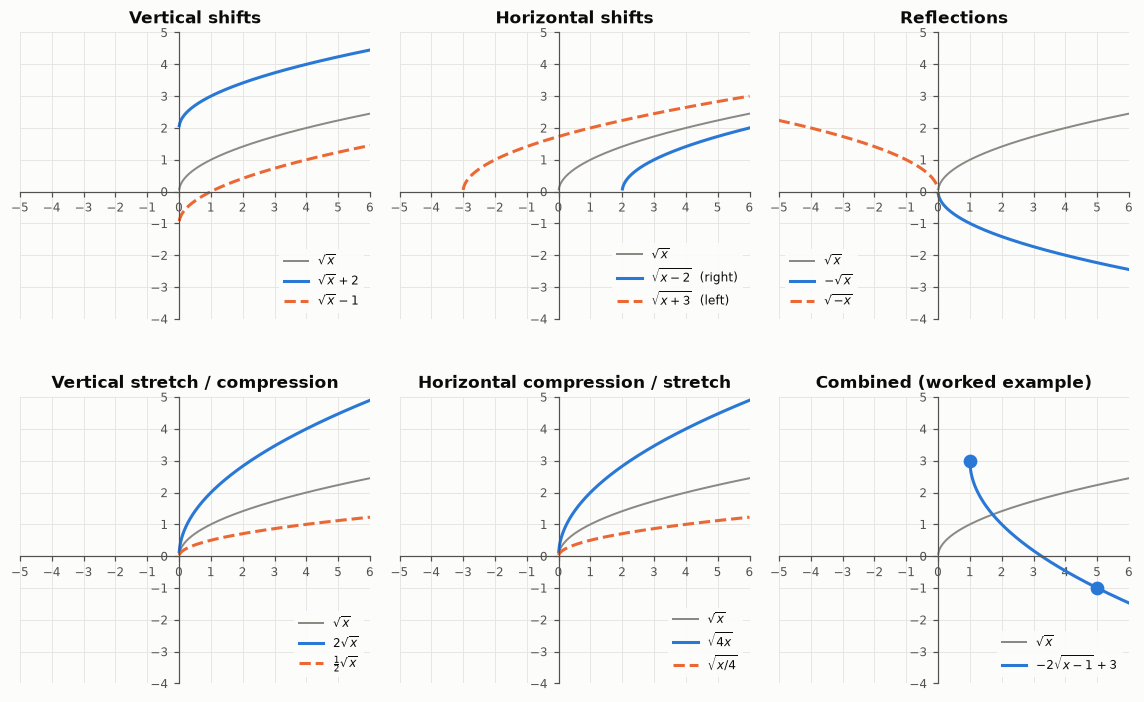

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 7))
x = np.linspace(-6, 6, 1200)
def r(t): return np.where(t >= 0, np.sqrt(np.clip(t, 0, None)), np.nan)
panels = [
    ("Vertical shifts", [(r(x) + 2, r"$\sqrt{x} + 2$", BLUE, "-"), (r(x) - 1, r"$\sqrt{x} - 1$", ORANGE, "--")]),
    ("Horizontal shifts", [(r(x - 2), r"$\sqrt{x - 2}$  (right)", BLUE, "-"), (r(x + 3), r"$\sqrt{x + 3}$  (left)", ORANGE, "--")]),
    ("Reflections", [(-r(x), r"$-\sqrt{x}$", BLUE, "-"), (r(-x), r"$\sqrt{-x}$", ORANGE, "--")]),
    ("Vertical stretch / compression", [(2*r(x), r"$2\sqrt{x}$", BLUE, "-"), (0.5*r(x), r"$\frac{1}{2}\sqrt{x}$", ORANGE, "--")]),
    ("Horizontal compression / stretch", [(r(4*x), r"$\sqrt{4x}$", BLUE, "-"), (r(x/4), r"$\sqrt{x/4}$", ORANGE, "--")]),
    ("Combined (worked example)", [(-2*r(x - 1) + 3, r"$-2\sqrt{x - 1} + 3$", BLUE, "-")]),
]
for ax, (title, curves) in zip(axes.flat, panels):
    setup(ax, (-5, 6), (-4, 5), title)
    ax.plot(x, r(x), color=GRAY, lw=1.3, label=r"$\sqrt{x}$")
    for y, lab, c, ls in curves: ax.plot(x, y, color=c, ls=ls, label=lab)
    ax.legend(loc="lower right" if title != "Reflections" else "lower left", fontsize=8)
ax = axes[1, 2]; dot(ax, 1, 3); dot(ax, 5, -1)
plt.tight_layout(); plt.show()

### Combining transformations

- **Vertical**, $a f(x) + k$: stretch/reflect by $a$ first, then shift by $k$ (order of operations on the output).
- **Horizontal**, $f(bx + p)$: factor first, $f\big(b(x + \tfrac{p}{b})\big)$, then compress/stretch by $\tfrac{1}{b}$ and shift by $\tfrac{p}{b}$. (The book's version, shift by $p$ then scale by $\tfrac{1}{b}$, gives the same graph.)
- A vertical and a horizontal transformation can be done in either order.

**Worked example.** $g(x) = -2\sqrt{x - 1} + 3$ from $\sqrt{x}$: right 1, stretch by 2, reflect across the $x$-axis, up 3. Track points:

$$
(0, 0) \to (1, 0) \to (1, 0) \to (1, 0) \to (1, 3), \qquad
(4, 2) \to (5, 2) \to (5, 4) \to (5, -4) \to (5, -1)
$$

**Worked example (horizontal).** $\sqrt{2x + 4} = \sqrt{2(x + 2)}$: compress by $\tfrac{1}{2}$, then shift **left 2**, not left 4. Check: the starting point needs $2x + 4 = 0$, so $x = -2$.

### Even and odd functions

| Type | Algebraic test | Symmetry | Examples |
|---|---|---|---|
| Even | $f(-x) = f(x)$ | across the $y$-axis | $x^2$, $\lvert x \rvert$, $x^4 - 3x^2$ |
| Odd | $f(-x) = -f(x)$ | about the origin (180° rotation) | $x$, $x^3$, $\dfrac{1}{x}$, $\sqrt[3]{x}$ |
| Neither | neither holds | none of these | $x^2 + x$, $x^3 + 1$, $\sqrt{x}$ |

To test, compute $f(-x)$ and simplify, then compare it with $f(x)$ and with $-f(x)$. For $f(x) = x^3 - x$: $f(-x) = -x^3 + x = -(x^3 - x) = -f(x)$, so $f$ is odd.

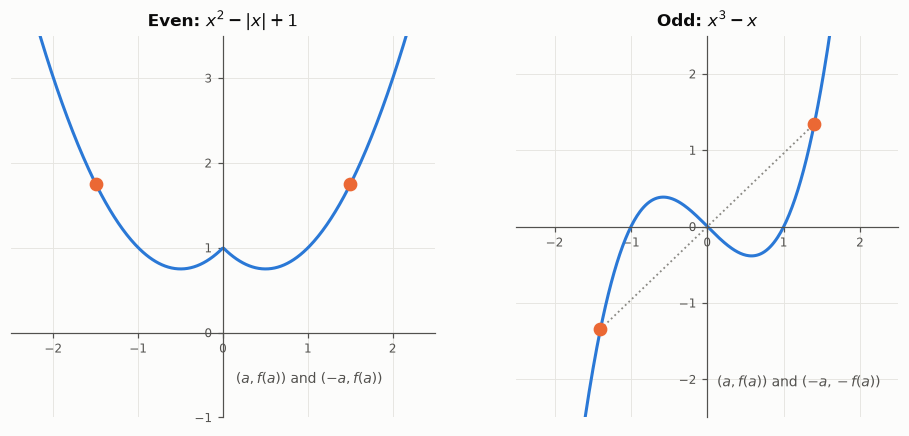

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
x = np.linspace(-2.5, 2.5, 400)
ax = axes[0]; setup(ax, (-2.5, 2.5), (-1, 3.5), r"Even: $x^2 - |x| + 1$")
ax.plot(x, x**2 - np.abs(x) + 1, color=BLUE)
for a in (1.5,): dot(ax, a, a**2 - a + 1, color=ORANGE); dot(ax, -a, a**2 - a + 1, color=ORANGE)
ax.text(0.15, -0.6, r"$(a, f(a))$ and $(-a, f(a))$", ha="left", color=INK2, fontsize=9)
ax = axes[1]; setup(ax, (-2.5, 2.5), (-2.5, 2.5), r"Odd: $x^3 - x$")
ax.plot(x, x**3 - x, color=BLUE)
a = 1.4; b = a**3 - a
dot(ax, a, b, color=ORANGE); dot(ax, -a, -b, color=ORANGE)
ax.plot([-a, a], [-b, b], color=GRAY, ls=":", lw=1.2)
ax.text(1.2, -2.1, r"$(a, f(a))$ and $(-a, -f(a))$", ha="center", color=INK2, fontsize=9)
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- $f(x - 3)$ moves the graph **right** 3, not left.
- $f(2x)$ **compresses** horizontally by $\tfrac{1}{2}$; it does not stretch.
- Confusing $-f(x)$ (flip over the $x$-axis) with $f(-x)$ (flip over the $y$-axis).
- In $f(bx + p)$, shifting by $p$ after scaling. Factor out $b$ first, then shift by $\tfrac{p}{b}$.
- Judging even/odd by looking at the exponents. $x^3 + 1$ has an odd power but is neither; always compute $f(-x)$.
:::

:::{important} The book underplays this
Book problems written as $f(bx + p)$ invite the wrong shift. Factoring out $b$, $f\big(b(x + \tfrac{p}{b})\big)$, makes the shift read off directly, and it is the form you'll use when you transform trig functions in Chapter 8 and probability densities later.
:::

:::{tip} Where this shows up
**Location-scale families.** If $Z$ has density $\phi(z)$, then $X = \mu + \sigma Z$ has density $\dfrac{1}{\sigma}\,\phi\!\left(\dfrac{x - \mu}{\sigma}\right)$: shift right $\mu$, stretch horizontally by $\sigma$, and compress vertically by $\tfrac{1}{\sigma}$ so the area stays 1. Standardizing, $z = \dfrac{x - \mu}{\sigma}$, undoes it. Centering and scaling covariates before fitting a model in PyMC is the same move. The standard normal density is even, which is why its odd moments are 0.
:::

(sec-3-6)=
## 3.6 Absolute Value Functions

### Absolute value as distance

$$
\lvert x \rvert =
\begin{cases}
x, & x \ge 0 \\
-x, & x < 0
\end{cases}
$$

- $\lvert x \rvert$ is the distance from $x$ to $0$; $\lvert x - a \rvert$ is the distance from $x$ to $a$.
- "Within $0.5$ of $10$" translates to $\lvert x - 10 \rvert \le 0.5$, i.e., $9.5 \le x \le 10.5$.

### The graph of $f(x) = a\lvert x - h \rvert + k$

A V shape with its **corner (vertex) at $(h, k)$**. It opens up if $a > 0$ and down if $a < 0$, and the two arms have slopes $\pm a$. This is the §3.5 rules applied to $\lvert x \rvert$.

### Absolute value equations

**Isolate the absolute value first**, then use

| Equation $\lvert A \rvert = B$ | Solutions |
|---|---|
| $B > 0$ | $A = B$ **or** $A = -B$ (two equations) |
| $B = 0$ | $A = 0$ (one equation) |
| $B < 0$ | no solution |

**Worked example.**

$$
\begin{aligned}
2\lvert x - 3 \rvert + 1 &= 9 \\
\lvert x - 3 \rvert &= 4 \\
x - 3 = 4 \quad &\text{or} \quad x - 3 = -4 \\
x = 7 \quad &\text{or} \quad x = -1
\end{aligned}
$$

Graphically, the solutions are the $x$-values where $y = 2\lvert x - 3 \rvert + 1$ meets the line $y = 9$.

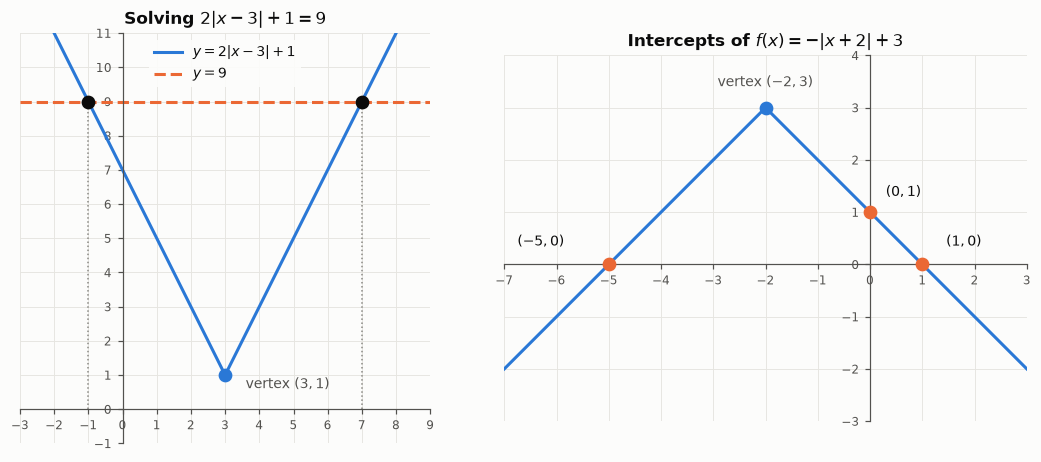

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.3))
x = np.linspace(-3, 9, 400)
ax = axes[0]; setup(ax, (-3, 9), (-1, 11), r"Solving $2|x - 3| + 1 = 9$")
ax.plot(x, 2*np.abs(x - 3) + 1, color=BLUE, label=r"$y = 2|x - 3| + 1$")
ax.axhline(9, color=ORANGE, ls="--", label="$y = 9$")
dot(ax, -1, 9, color=INK); dot(ax, 7, 9, color=INK); dot(ax, 3, 1)
ax.plot([-1, -1], [0, 9], color=GRAY, ls=":", lw=1); ax.plot([7, 7], [0, 9], color=GRAY, ls=":", lw=1)
ax.text(3.6, 0.6, "vertex $(3, 1)$", ha="left", color=INK2, fontsize=9)
ax.legend(loc="upper center", fontsize=9)

x = np.linspace(-7, 3, 400)
ax = axes[1]; setup(ax, (-7, 3), (-3, 4), r"Intercepts of $f(x) = -|x + 2| + 3$")
ax.plot(x, -np.abs(x + 2) + 3, color=BLUE)
for p in [(-5, 0), (1, 0), (0, 1)]: dot(ax, *p, color=ORANGE)
dot(ax, -2, 3)
ax.text(-2, 3.4, "vertex $(-2, 3)$", ha="center", color=INK2, fontsize=9)
ax.text(-6.3, 0.35, "$(-5, 0)$", ha="center", fontsize=9); ax.text(1.8, 0.35, "$(1, 0)$", ha="center", fontsize=9)
ax.text(0.3, 1.3, "$(0, 1)$", fontsize=9)
plt.tight_layout(); plt.show()

For $f(x) = -\lvert x + 2 \rvert + 3$: the $y$-intercept is $f(0) = -2 + 3 = 1$; the $x$-intercepts come from $\lvert x + 2 \rvert = 3$, so $x = 1$ or $x = -5$.

### Absolute value inequalities (Extensions exercises)

For $b > 0$:

| Inequality | Equivalent | Picture |
|---|---|---|
| $\lvert x - a \rvert < b$ | $a - b < x < a + b$ | one interval, within $b$ of $a$ |
| $\lvert x - a \rvert > b$ | $x < a - b$ or $x > a + b$ | two rays, farther than $b$ from $a$ |

:::{admonition} Common mistakes
:class: warning
- Splitting into $\pm$ before isolating. In $2\lvert x - 3 \rvert + 1 = 9$, subtract 1 and divide by 2 *first*.
- $\lvert x + 2 \rvert \ne \lvert x \rvert + 2$. Absolute value does not distribute over a sum.
- Solving $\lvert A \rvert = -5$ anyway. A distance can't be negative, so there is no solution.
- Writing $\lvert x - a \rvert > b$ as a single interval $a - b > x > a + b$, which no $x$ satisfies.
:::

:::{tip} Where this shows up
Absolute error and mean absolute deviation are built on $\lvert x_i - c \rvert$, and the median is the value of $c$ that minimizes $\sum \lvert x_i - c \rvert$. The Laplace distribution has density proportional to $e^{-\lvert x - \mu \rvert / b}$, which is the Bayesian version of the lasso penalty. A margin-of-error statement $\lvert \bar{x} - \mu \rvert \le E$ is an absolute value inequality.
:::

(sec-3-7)=
## 3.7 Inverse Functions

### Definition

If $f$ is one-to-one, its **inverse** $f^{-1}$ undoes it: $f^{-1}(y) = x$ exactly when $f(x) = y$. Equivalently,

$$
f^{-1}\big(f(x)\big) = x \ \text{ for all } x \in \operatorname{dom} f,
\qquad
f\big(f^{-1}(x)\big) = x \ \text{ for all } x \in \operatorname{dom} f^{-1}.
$$

| | $f$ | $f^{-1}$ |
|---|---|---|
| Domain | $D$ | range of $f$ |
| Range | $R$ | $D$ |
| Point on graph | $(a, b)$ | $(b, a)$ |
| Table | input row / output row | swap the rows |

- An inverse exists **only if $f$ is one-to-one** (passes the horizontal line test).
- If $f$ is not one-to-one, **restrict its domain** to a piece where it is. $f(x) = x^2$ on $[0, \infty)$ has inverse $\sqrt{x}$.
- $f^{-1}(x)$ is **not** $\dfrac{1}{f(x)}$. The $-1$ is notation, not an exponent.
- The graph of $f^{-1}$ is the reflection of the graph of $f$ across the line $y = x$.

### Finding an inverse from a formula

1. Write $y = f(x)$.
2. Solve for $x$ in terms of $y$.
3. Swap the labels: the result is $f^{-1}(x)$.
4. Verify with **both** compositions.

**Worked example.** $f(x) = \dfrac{2x + 3}{x - 1}$, with domain $x \ne 1$.

$$
\begin{aligned}
y(x - 1) &= 2x + 3 \\
xy - y &= 2x + 3 \\
xy - 2x &= y + 3 \\
x(y - 2) &= y + 3 \implies x = \frac{y + 3}{y - 2}
\qquad\Longrightarrow\qquad f^{-1}(x) = \frac{x + 3}{x - 2}
\end{aligned}
$$

The domain of $f^{-1}$ is $x \ne 2$, so the range of $f$ is $y \ne 2$. Verify:

$$
f\big(f^{-1}(x)\big) = \frac{2\cdot\frac{x + 3}{x - 2} + 3}{\frac{x + 3}{x - 2} - 1}
= \frac{\frac{2x + 6 + 3x - 6}{x - 2}}{\frac{x + 3 - x + 2}{x - 2}}
= \frac{5x}{5} = x
$$

The key step for solving is collecting every $x$ term on one side and factoring $x$ out.

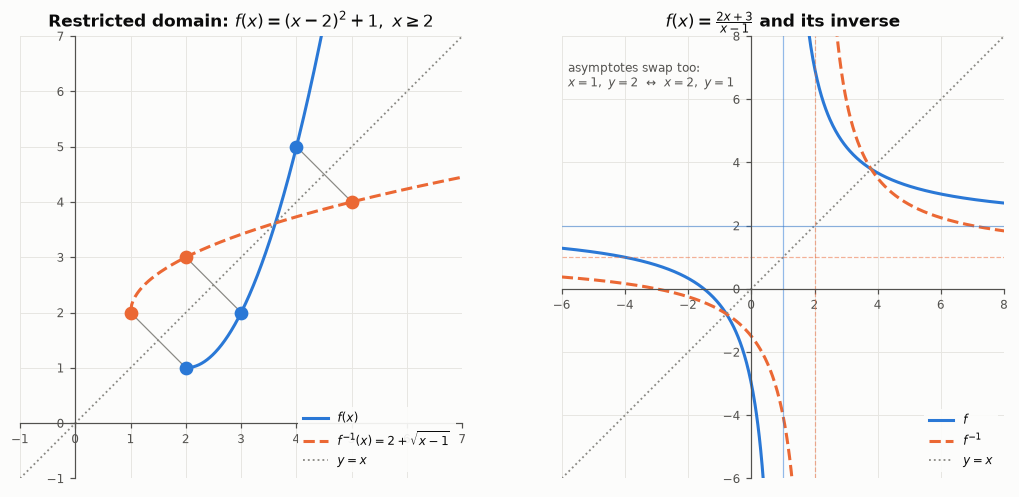

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
ax = axes[0]; setup(ax, (-1, 7), (-1, 7), r"Restricted domain: $f(x) = (x - 2)^2 + 1,\ x \geq 2$")
x = np.linspace(2, 4.45, 300); xi = np.linspace(1, 7, 300)
ax.plot(x, (x - 2)**2 + 1, color=BLUE, label=r"$f(x)$")
ax.plot(xi, 2 + np.sqrt(xi - 1), color=ORANGE, ls="--", label=r"$f^{-1}(x) = 2 + \sqrt{x - 1}$")
ax.plot([-1, 7], [-1, 7], color=GRAY, lw=1.2, ls=":", label="$y = x$")
for (a, b) in [(2, 1), (3, 2), (4, 5)]:
    dot(ax, a, b, color=BLUE); dot(ax, b, a, color=ORANGE)
    ax.plot([a, b], [b, a], color=GRAY, lw=0.8)
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]; setup(ax, (-6, 8), (-6, 8), r"$f(x) = \frac{2x + 3}{x - 1}$ and its inverse", ticks=2)
for lo, hi in [(-6, 0.7), (1.3, 8)]:
    x = np.linspace(lo, hi, 300); y = (2*x + 3)/(x - 1)
    ax.plot(x, np.where(np.abs(y) > 8.5, np.nan, y), color=BLUE, label=r"$f$" if lo < 0 else None)
for lo, hi in [(-6, 1.7), (2.3, 8)]:
    x = np.linspace(lo, hi, 300); y = (x + 3)/(x - 2)
    ax.plot(x, np.where(np.abs(y) > 8.5, np.nan, y), color=ORANGE, ls="--", label=r"$f^{-1}$" if lo < 0 else None)
ax.plot([-6, 8], [-6, 8], color=GRAY, lw=1.2, ls=":", label="$y = x$")
ax.axvline(1, color=BLUE, lw=0.8, alpha=0.5); ax.axhline(2, color=BLUE, lw=0.8, alpha=0.5)
ax.axvline(2, color=ORANGE, lw=0.8, alpha=0.5, ls="--"); ax.axhline(1, color=ORANGE, lw=0.8, alpha=0.5, ls="--")
ax.legend(loc="lower right", fontsize=8)
ax.text(-5.8, 7.2, "asymptotes swap too:\n$x = 1,\\ y = 2$  ↔  $x = 2,\\ y = 1$", color=INK2, fontsize=8, va="top")
plt.tight_layout(); plt.show()

:::{admonition} Common mistakes
:class: warning
- Writing $f^{-1}(x) = \dfrac{1}{f(x)}$.
- Swapping $x$ and $y$ and then not finishing the solve. The inverse must be written with $y$ isolated (or $x$ isolated before swapping).
- Picking the wrong sign when solving introduces a $\pm$. With the domain restricted to $x \ge 2$, $x - 2 = +\sqrt{y - 1}$, not $-\sqrt{y - 1}$.
- Forgetting that the domain of $f^{-1}$ is the range of $f$. If $f(x) = \sqrt{x - 3}$, then $f^{-1}(x) = x^2 + 3$ only for $x \ge 0$.
:::

:::{important} The book underplays this
Verifying an inverse needs **both** compositions, each on the right domain. $g(x) = x^2$ satisfies $g\big(\sqrt{x}\big) = x$ for every $x \ge 0$, yet $\sqrt{g(x)} = \lvert x \rvert$, which equals $x$ only for $x \ge 0$. The two checks only agree once $g$'s domain is restricted.
:::

:::{tip} Where this shows up
The **quantile function** is the inverse of a CDF: the median is $F^{-1}(0.5)$, and a 95% interval uses $F^{-1}(0.025)$ and $F^{-1}(0.975)$. **Inverse transform sampling** generates random draws with $X = F^{-1}(U)$, where $U$ is uniform on $(0, 1)$. In GLMs, the link function (logit, log) and the inverse link (logistic, exp) are inverse pairs. Back-transforming an estimate from the log scale with $e^{x}$ is applying an inverse. Logs and exponentials as inverses are Chapter 6.
:::